In [1]:
import pandas as pd
import numpy as np
import os

print("Employee Performance Evaluation System")
print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Employee Performance Evaluation System
Current folder: C:\Users\akash
Files available: ['-1.14-windows.xml', '.claude', '.claude.json', '.conda', '.condarc', '.continuum', '.gitconfig', '.idea', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jdks', '.junie', '.jupyter', '.lesshst', '.m2', '.matplotlib', '.ms-ad', '.packettracer', '.pdfbox.cache', '.spss', '.vscode', '.vscode-shared', '55.pdf', 'a3.App.log', 'a3.cod', 'a3.cut', 'a3.emf', 'a3.png', 'a3.sbk', 'a3.slg', 'a3.STD', 'a3.STD.metadata', 'a3.uid', 'akanksha', 'Akanksha chorage -Explain MIS in brief also write the purpose of mis in any\xa0organisation.docx', 'AKASH 1.pdf', 'Akash chorage Resume.pdf', 'app.py', 'AppData', 'Application Data', 'ASSIGNMENT 02 PROBLLEM NO 01 B.App.log', 'ASSIGNMENT 02 PROBLLEM NO 01 B.cod', 'ASSIGNMENT 02 PROBLLEM NO 01 B.cut', 'ASSIGNMENT 02 PROBLLEM NO 01 B.emf', 'ASSIGNMENT 02 PROBLLEM NO 01 B.png', 'ASSIGNMENT 02 PROBLLEM NO 01 B.sbk', 'ASSIGNMENT 02 PROBLLEM NO 01 B.slg', 'ASSIGNMENT 02 PROBLLEM 

In [2]:
data = pd.read_csv("employee_performance.csv")

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (10, 5)


,experience_years,attendance_percent,projects_completed,manager_rating,performance
0,1,65,1,2,Low
1,2,72,2,2,Low
2,3,80,3,3,Medium
3,4,85,4,3,Medium
4,5,90,6,4,High


In [6]:
import pandas as pd 

data = pd.read_csv("employee_performance.csv")

print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

display(data.head(10))

Dataset shape: (10, 5)

Column names:
['experience_years', 'attendance_percent', 'projects_completed', 'manager_rating', 'performance']


,experience_years,attendance_percent,projects_completed,manager_rating,performance
0,1,65,1,2,Low
1,2,72,2,2,Low
2,3,80,3,3,Medium
3,4,85,4,3,Medium
4,5,90,6,4,High
5,6,92,7,5,High
6,7,95,8,5,High
7,2,60,1,1,Low
8,4,88,5,4,Medium
9,5,93,6,5,High


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#separate input features and target 
x = data.drop("performance", axis=1)
y = data["performance"]

#split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.3, random_state=42, stratify=y
)

#Train the model
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

#evaluate the model
y_pred = model.predict(x_test)

print("Actual values:", y_test.tolist())
print("Predicted values:", y_pred.tolist())
print("Accuracy:", accuracy_score(y_test,y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Actual values: ['Medium', 'Low', 'High']
Predicted values: ['Medium', 'Low', 'High']
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         1
         Low       1.00      1.00      1.00         1
      Medium       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [16]:
# Sample employee details
sample_employee = pd.DataFrame([{
    "experience_years": 3,
    "attendance_percent": 82,
    "projects_completed": 4,
    "manager_rating": 3
}])

# Predict performance
prediction = model.predict(sample_employee)

print("Predicted Employee Performance:", prediction[0])

Predicted Employee Performance: Medium


In [18]:
import pickle 

with open("employee_performance_model.pkl", "wb") as f:
    pickle.dump(model, f)
    
print("Model saved successfully!")

Model saved successfully!


In [20]:
%pip install flask

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [22]:
%%writefile app.py
from flask import Flask, render_template, request
import pandas as pd
import pickle
import os

app = Flask(__name__)

# Load trained ML model
with open("employee_performance_model.pkl", "rb") as f:
    model = pickle.load(f)

@app.route("/", methods=["GET", "POST"])
def home():
    prediction = None
    error = None

    if request.method == "POST":
        try:
            experience = float(request.form["experience"])
            attendance = float(request.form["attendance"])
            projects = int(request.form["projects"])
            rating = float(request.form["rating"])

            if experience < 0:
                raise ValueError("Experience cannot be negative.")
            if not 0 <= attendance <= 100:
                raise ValueError("Attendance must be between 0 and 100.")
            if projects < 0:
                raise ValueError("Projects cannot be negative.")
            if not 1 <= rating <= 5:
                raise ValueError("Rating must be between 1 and 5.")

            employee = pd.DataFrame([{
                "experience_years": experience,
                "attendance_percent": attendance,
                "projects_completed": projects,
                "manager_rating": rating
            }])

            prediction = model.predict(employee)[0]

        except ValueError as e:
            error = str(e)

    return render_template(
        "index.html",
        prediction=prediction,
        error=error
    )

if __name__ == "__main__":
    app.run(debug=True, use_reloader=False)

Overwriting app.py


In [24]:
import os

os.makedirs("templates", exist_ok=True)

print("Templates folder ready!")

Templates folder ready!


In [28]:

%%writefile templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Employee Performance Evaluation</title>

    <style>
        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            font-family: Arial, sans-serif;
            background: #f1f5f9;
            color: #1e293b;
        }

        header {
            background: #172b4d;
            color: white;
            padding: 25px 20px;
            text-align: center;
        }

        header h1 {
            margin: 0 0 8px;
            font-size: 28px;
        }

        header p {
            margin: 0;
            color: #dbeafe;
        }

        .container {
            max-width: 850px;
            margin: 30px auto;
            padding: 0 18px;
        }

        .intro {
            background: white;
            padding: 20px;
            border-radius: 12px;
            margin-bottom: 20px;
            box-shadow: 0 4px 15px #172b4d12;
        }

        .intro h2 {
            margin-top: 0;
            color: #172b4d;
        }

        .form-card {
            background: white;
            padding: 28px;
            border-radius: 14px;
            box-shadow: 0 6px 22px #172b4d14;
        }

        .form-card h2 {
            margin-top: 0;
            color: #172b4d;
        }

        .form-grid {
            display: grid;
            grid-template-columns: 1fr 1fr;
            gap: 20px;
        }

        label {
            display: block;
            font-weight: bold;
            margin-bottom: 8px;
            font-size: 14px;
        }

        input {
            width: 100%;
            padding: 13px;
            border: 1px solid #cbd5e1;
            border-radius: 8px;
            font-size: 15px;
        }

        input:focus {
            outline: 2px solid #93c5fd;
            border-color: #2563eb;
        }

        button {
            width: 100%;
            margin-top: 24px;
            padding: 14px;
            background: #2563eb;
            color: white;
            border: none;
            border-radius: 8px;
            font-size: 16px;
            font-weight: bold;
            cursor: pointer;
        }

        button:hover {
            background: #1d4ed8;
        }

        .result {
            margin-top: 22px;
            padding: 20px;
            border-radius: 10px;
            background: #ecfdf5;
            border: 1px solid #a7f3d0;
            color: #065f46;
            text-align: center;
        }

        .result h2 {
            margin: 0 0 8px;
        }

        .error {
            margin-top: 20px;
            padding: 14px;
            background: #fef2f2;
            color: #b91c1c;
            border-radius: 8px;
        }

        .note {
            margin-top: 20px;
            color: #64748b;
            font-size: 12px;
            line-height: 1.6;
        }

        footer {
            text-align: center;
            padding: 20px;
            color: #64748b;
            font-size: 12px;
        }

        @media (max-width: 600px) {
            .form-grid {
                grid-template-columns: 1fr;
            }

            header h1 {
                font-size: 23px;
            }

            .form-card {
                padding: 20px;
            }
        }
    </style>
</head>

<body>
    <header>
        <h1>Employee Performance Evaluation</h1>
        <p>Machine Learning Based Performance Prediction</p>
    </header>

    <main class="container">
        <section class="intro">
            <h2>Welcome to the Dashboard</h2>
            <p>
                Enter the employee's details below to generate a
                performance prediction using the trained ML model.
            </p>
        </section>

        <section class="form-card">
            <h2>Employee Details</h2>

            <form method="POST">
                <div class="form-grid">
                    <div>
                        <label for="experience">Experience (years)</label>
                        <input id="experience" type="number"
                               name="experience" min="0" step="any"
                               placeholder="e.g. 3" required>
                    </div>

                    <div>
                        <label for="attendance">Attendance (%)</label>
                        <input id="attendance" type="number"
                               name="attendance" min="0" max="100"
                               step="any" placeholder="e.g. 82" required>
                    </div>

                    <div>
                        <label for="projects">Projects Completed</label>
                        <input id="projects" type="number"
                               name="projects" min="0" step="1"
                               placeholder="e.g. 4" required>
                    </div>

                    <div>
                        <label for="rating">Manager Rating (1–5)</label>
                        <input id="rating" type="number"
                               name="rating" min="1" max="5"
                               step="any" placeholder="e.g. 3" required>
                    </div>
                </div>

                <button type="submit">Predict Performance</button>
            </form>

            {% if prediction %}
            <div class="result">
                <h2>Prediction: {{ prediction }}</h2>
                <p>Result generated by the trained machine learning model.</p>
            </div>
            {% endif %}

            {% if error %}
            <div class="error">{{ error }}</div>
            {% endif %}

            <p class="note">
                Educational prototype only. The current dataset contains
                very few records, so predictions may be unreliable.
                This output should not be used for real employment decisions.
            </p>
        </section>
    </main>

    <footer>
        Employee Performance Evaluation System | Python + Flask + ML
    </footer>
</body>
</html>


Overwriting templates/index.html


In [26]:
import subprocess
import sys

process = subprocess.Popen(
    [sys.executable, "app.py"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("Flask process started. PID:", process.pid)

Flask process started. PID: 28240


In [27]:
import time
import urllib.request

time.sleep(2)

try:
    response = urllib.request.urlopen("http://127.0.0.1:5000", timeout=5)
    print("Dashboard status:", response.status)
    print("Open this URL: http://127.0.0.1:5000")
except Exception as e:
    print("Error:", e)

Dashboard status: 200
Open this URL: http://127.0.0.1:5000


,Predicted Low,Predicted Medium,Predicted High
Actual Low,1,0,0
Actual Medium,0,1,0
Actual High,0,0,1


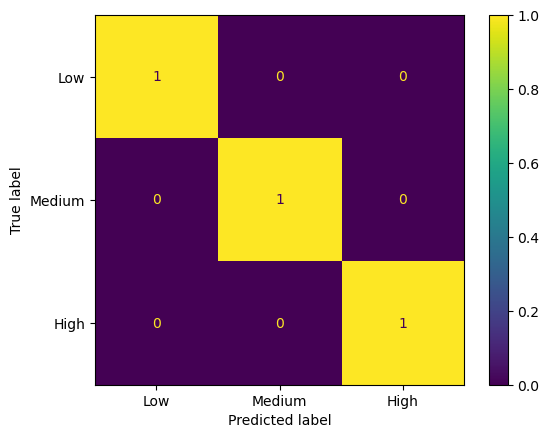

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare actual and predicted test values
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

display(pd.DataFrame(
    cm,
    index=["Actual Low", "Actual Medium", "Actual High"],
    columns=["Predicted Low", "Predicted Medium", "Predicted High"]
))

# Visualize results
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)
disp.plot()
plt.show()

In [30]:
import pickle

with open("employee_performance_model.pkl", "wb") as f:
    pickle.dump(model, f)

print("Updated model saved successfully!")

Updated model saved successfully!


In [31]:

import os

print("Project files:")

files = [
    "app.py",
    "employee_performance.csv",
    "employee_performance_model.pkl",
    "templates/index.html"
]

for file in files:
    print(file, "->", os.path.exists(file))


Project files:
app.py -> True
employee_performance.csv -> True
employee_performance_model.pkl -> True
templates/index.html -> True


In [32]:

import os
import shutil

project_folder = r"C:\Users\akash\Employee_Performance_Project"

os.makedirs(project_folder, exist_ok=True)
os.makedirs(os.path.join(project_folder, "templates"), exist_ok=True)

files = [
    "app.py",
    "employee_performance.csv",
    "employee_performance_model.pkl"
]

for file in files:
    shutil.copy2(file, os.path.join(project_folder, file))

shutil.copy2(
    "templates/index.html",
    os.path.join(project_folder, "templates", "index.html")
)

print("Project files copied successfully!")
print("Project location:", project_folder)


Project files copied successfully!
Project location: C:\Users\akash\Employee_Performance_Project


In [33]:

import subprocess
import sys
import time
import urllib.request

project_folder = r"C:\Users\akash\Employee_Performance_Project"

process = subprocess.Popen(
    [sys.executable, "app.py"],
    cwd=project_folder
)

time.sleep(3)

try:
    response = urllib.request.urlopen(
        "http://127.0.0.1:5000",
        timeout=5
    )
    print("Dashboard status:", response.status)
    print("Open this URL: http://127.0.0.1:5000")
except Exception as e:
    print("Error:", e)


Dashboard status: 200
Open this URL: http://127.0.0.1:5000
